# Аналіз Ames Housing

Усі обчислення нижче виконуються лише на навчальній частині після розбиття 70/15/15.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if (Path.cwd() / "core.py").exists() else Path.cwd().parent
sys.path.insert(0, str(root))
from core import load_data, NUM as NUMERIC, CAT as CATEGORICAL
train, validation, test = load_data()
print("Навчальна частина:", train.shape)
train.head()

Навчальна частина: (1022, 13)


,OverallQual,GrLivArea,FirstFlrSF,TotalBsmtSF,GarageCars,YearBuilt,YrSold,FullBath,TotRmsAbvGrd,Neighborhood,KitchenQual,CentralAir,SalePrice
135,7,1682,1682,1304,2,1970,2008,2,7,NWAmes,TA,Y,174000
1452,5,1072,1072,547,2,2005,2006,1,5,Edwards,TA,Y,145000
762,7,1547,764,756,2,2009,2010,2,7,Somerst,Gd,Y,215200
932,9,1905,1905,1905,3,2006,2007,2,8,Somerst,Ex,Y,320000
435,7,1661,827,799,2,1996,2009,2,6,CollgCr,Gd,Y,212000


In [2]:
train.dtypes

OverallQual      int64
GrLivArea        int64
FirstFlrSF       int64
TotalBsmtSF      int64
GarageCars       int64
YearBuilt        int64
YrSold           int64
FullBath         int64
TotRmsAbvGrd     int64
Neighborhood    object
KitchenQual     object
CentralAir      object
SalePrice        int64
dtype: object

In [3]:
train.isna().mean().sort_values(ascending=False)

OverallQual     0.0
GrLivArea       0.0
FirstFlrSF      0.0
TotalBsmtSF     0.0
GarageCars      0.0
YearBuilt       0.0
YrSold          0.0
FullBath        0.0
TotRmsAbvGrd    0.0
Neighborhood    0.0
KitchenQual     0.0
CentralAir      0.0
SalePrice       0.0
dtype: float64

In [4]:
train["SalePrice"].describe()

count      1022.000000
mean     181312.692759
std       77617.461005
min       34900.000000
25%      130000.000000
50%      165000.000000
75%      215000.000000
max      745000.000000
Name: SalePrice, dtype: float64

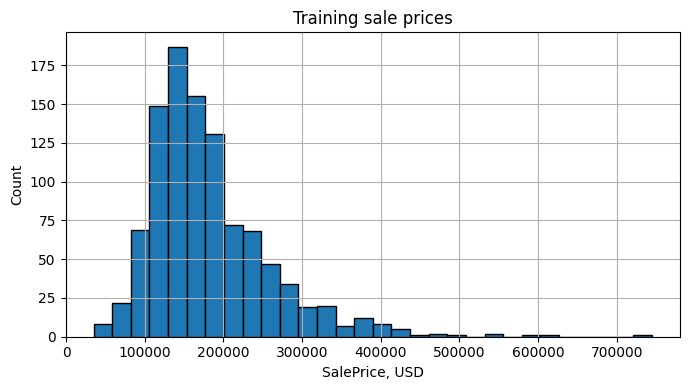

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
train["SalePrice"].hist(bins=30, ax=ax, edgecolor="black")
ax.set(xlabel="SalePrice, USD", ylabel="Count", title="Training sale prices")
fig.tight_layout()
fig.savefig(root / "docs/saleprice_train.png", dpi=160)
plt.show()

In [6]:
train[NUMERIC + ["SalePrice"]].corr()["SalePrice"].sort_values(ascending=False)

SalePrice       1.000000
OverallQual     0.784720
GrLivArea       0.689238
GarageCars      0.642689
TotalBsmtSF     0.590017
FirstFlrSF      0.583132
FullBath        0.549164
TotRmsAbvGrd    0.519634
YearBuilt       0.512206
YrSold         -0.012761
Name: SalePrice, dtype: float64

In [7]:
train["Neighborhood"].value_counts()

Neighborhood
NAmes      155
CollgCr    109
OldTown     82
Edwards     79
Somerst     57
NWAmes      54
Gilbert     52
NridgHt     50
Sawyer      48
BrkSide     41
SawyerW     38
Crawfor     38
Mitchel     34
NoRidge     28
Timber      27
IDOTRR      24
StoneBr     20
ClearCr     19
SWISU       16
Blmngtn     14
BrDale      12
MeadowV     10
Veenker      8
NPkVill      6
Blueste      1
Name: count, dtype: int64

In [8]:
counts = train["Neighborhood"].value_counts()
rare = counts[counts / len(train) < 0.01]
print("Рідкісні райони:")
print(rare)
summary = {"shape": list(train.shape),
           "missing_counts": train.isna().sum().to_dict(),
           "missing_fraction": train.isna().mean().to_dict(),
           "target": train["SalePrice"].describe().to_dict(),
           "correlations": train[NUMERIC + ["SalePrice"]].corr()["SalePrice"].to_dict(),
           "neighborhood_counts": counts.to_dict(),
           "rare_neighborhoods": rare.to_dict(),
           "category_counts": {column: int(train[column].nunique()) for column in CATEGORICAL}}
(root / "docs/eda_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

Рідкісні райони:
Neighborhood
MeadowV    10
Veenker     8
NPkVill     6
Blueste     1
Name: count, dtype: int64


1943

## Рішення

Числові пропуски заповнюються медіанами train; для підвалу й гаража використовується нуль. Категоріальні пропуски заповнюються найчастішими значеннями train. Рідкісні райони об’єднуються в Other. Через різні масштаби числових ознак для Ridge порівнюються standard і minmax. Дорогі будинки не видаляються автоматично, їхній вплив оцінюється за MAE і RMSE. Детальні висновки наведені у звіті.